# Prioritize interactions for validation - November 4, 2016
Filter the full TPS-predicted EGFR pathway to prioritize interactions for RNAi screening.  Explore the directed edges in the pathway to see how many involve kinases or phosphatases.

## Initialize

In [1]:
%pylab inline
import pandas as pd
from matplotlib_venn import venn3_unweighted
import os

kinase_file = os.path.join('..','..','UniProt','uniprot-kinase-110416.txt')
phosphatase_file = os.path.join('..','..','UniProt','uniprot-phosphatase-110416.txt')
tps_network_file = os.path.join('..','..','synthesis072614','p-0.01_202dir.xlsx')
node_annotation_file = os.path.join('..','..','synthesis072614','cytoscapeAnnotations020715.txt')

Populating the interactive namespace from numpy and matplotlib


## Load the kinases and phosphatases
These are from UniProt keyword searches for human proteins performed on November 4, 2016
- keyword:"Protein phosphatase [KW-0904]" AND organism:"Homo sapiens (Human) [9606]"
- keyword:"Kinase [KW-0418]" AND organism:"Homo sapiens (Human) [9606]"


In [2]:
kinase_df = pd.read_csv(kinase_file, sep='\t')
phosphatase_df = pd.read_csv(phosphatase_file, sep='\t')
print 'Loaded {} kinases and {} phosphatases'.format(len(kinase_df), len(phosphatase_df))

Loaded 2716 kinases and 314 phosphatases


## Load the TPS pathway prediction
Make copies that include only the directed edges and only the directed, signed edges.

In [3]:
tps_df = pd.read_excel(tps_network_file, sheetname='p-0.01 first-prev monotonicity', convert_float=False)
tps_dir_df = tps_df[tps_df['Non-ambiguous direction']]
tps_dir_sig_df = tps_df[tps_df['Non-ambiguous sign and direction']]

print 'Loaded {} TPS pathway edges'.format(len(tps_df))
print 'Loaded {} TPS directed edges'.format(len(tps_dir_df))
print 'Loaded {} TPS directed and signed edges'.format(len(tps_dir_sig_df))

Loaded 413 TPS pathway edges
Loaded 202 TPS directed edges
Loaded 38 TPS directed and signed edges


## Load the TPS pathway annotations
This contains information about which nodes are Steiner nodes and which have phosphorylation changes (significant or insignificant).  It also tracks which are members of a reference EGFR pathway.

In [4]:
annot_df = pd.read_csv(node_annotation_file, sep='\t')
print 'Loaded annotations for {} nodes'.format(len(annot_df))
annot_df.head()

Loaded annotations for 739 nodes


,Protein,NodeType,ReferenceEGFR,SigPeptide1Log2FC,SigPeptide2Log2FC,SigPeptide3Log2FC,SigPeptide4Log2FC,SigPeptide5Log2FC,SigPeptide6Log2FC,InsigPeptide1Log2FC,...,ActivitySummary32Min,ActivitySummary64Min,ActivitySummary128Min,FirstActive,HeatMapBg1,HeatMapBg2,HeatMapBg3,HeatMapBg4,HeatMapBg5,HeatMapBg6
0,1433G_HUMAN,Steiner,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,2,"0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0"
1,1433Z_HUMAN,InsigPrize,False,NaN,NaN,NaN,NaN,NaN,NaN,"0, 0.023497, 0.027113, -0.015028, -0.119385, 0...",...,NaN,NaN,NaN,2,"0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0"
2,41_HUMAN,SigPrize,False,"0, 0.36918, -0.088325, -0.493456, -0.706793, -...",NaN,NaN,NaN,NaN,NaN,"0, 0.525056, 0.405297, 0.060709, 0.327423, 0.3...",...,0.0,0.0,0.0,2,"0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0"
3,4ET_HUMAN,Excluded,False,"0, 0.106206, 0.314831, 1.052917, 1.225798, 1.3...",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,Not active,"0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0"
4,A8K031_HUMAN,Steiner,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,2,"0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0","0, 0, 0, 0, 0, 0, 0"


## Compare the kinases, phosphatases, and TPS pathway proteins
Consider all pathway members and then only the regulators (source nodes) of directed edges.  Of 68 TPS proteins that are sources for a directed edge, only 22 are kinases and 1 is a phosphatase.  There are other kinases and phosphatases among the undirected edges.

68 TPS regulators


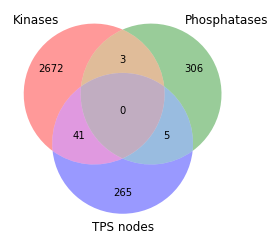

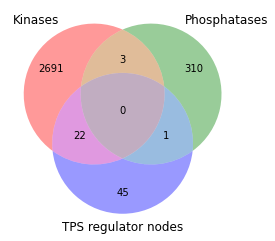

In [5]:
kinase_set = set(kinase_df['Entry name'])
phosphatase_set = set(phosphatase_df['Entry name'])
tps_node_set = set(tps_df['source'])
tps_node_set.update(tps_df['target'])
venn3_unweighted([kinase_set, phosphatase_set, tps_node_set], ['Kinases', 'Phosphatases', 'TPS nodes']);

figure();
tps_regulator_set = set(tps_dir_df['Ordered interaction source'])
print '{} TPS regulators'.format(len(tps_regulator_set))
venn3_unweighted([kinase_set, phosphatase_set, tps_regulator_set], ['Kinases', 'Phosphatases', 'TPS regulator nodes']);

## Filter kinase and phosphatase directed edges
Consider only the directed edges for which the source protein is a kinase or phosphatase.  This does not consider whether the target protein exhibited a significant phosphorylation change.

In [6]:
# Directed edges with a kinase as the source
tps_dir_kin_df = tps_dir_df[tps_dir_df['Ordered interaction source'].isin(kinase_set)]
print '{} of {} directed edges have a kinase as the source'.format(len(tps_dir_kin_df), len(tps_dir_df))
supported = len(tps_dir_kin_df[tps_dir_kin_df['Kinase-substrate'] == 'Y'])
print '{} are supported by a PhosphoSitePlus kinase-substrate interaction'.format(supported)
tps_kin_regulators = set(tps_dir_kin_df['Ordered interaction source'])
print 'The {} source kinases are:'.format(len(tps_kin_regulators))
print '\n'.join(sorted(tps_kin_regulators))

# Directed edge with a phosphatase as the source
tps_dir_phos_df = tps_dir_df[tps_dir_df['Ordered interaction source'].isin(phosphatase_set)]
print '\n{} of {} directed edges have a phosphatase as the source'.format(len(tps_dir_phos_df), len(tps_dir_df))
supported = len(tps_dir_phos_df[tps_dir_phos_df['Kinase-substrate'] == 'Y'])
print '{} are supported by a PhosphoSitePlus kinase-substrate interaction'.format(supported)
tps_phos_regulators = set(tps_dir_phos_df['Ordered interaction source'])
print 'The source phosphatase is:'
print '\n'.join(sorted(tps_phos_regulators))

101 of 202 directed edges have a kinase as the source
78 are supported by a PhosphoSitePlus kinase-substrate interaction
The 22 source kinases are:
ABL2_HUMAN
AKT1_HUMAN
ATM_HUMAN
CDK1_HUMAN
CDK5_HUMAN
CSK21_HUMAN
EGFR_HUMAN
EPHA2_HUMAN
EPHA3_HUMAN
FAK1_HUMAN
HIPK2_HUMAN
KAPCA_HUMAN
KKCC1_HUMAN
MARK2_HUMAN
MK01_HUMAN
MK03_HUMAN
MK09_HUMAN
MP2K1_HUMAN
NEK6_HUMAN
PAK1_HUMAN
PNKP_HUMAN
WNK1_HUMAN

1 of 202 directed edges have a phosphatase as the source
0 are supported by a PhosphoSitePlus kinase-substrate interaction
The source phosphatase is:
PP1B_HUMAN


## Do the directed edges with kinase and phosphatase regulators involve significantly phosphorylated targets?
These edges could be the most interesting for further experiments.  This ignores the direction of the phosphorylation change.  There are many directed edges where the kinase is a source but the target does not significantly change in phosphorylation.  These could be observed insignificant changes, false negatives in the mass spec, or incorrect predictions.

We already tested some of the 33 kinase-substrate interactions that have significant phosphorylation changes on the target protein:
- ABL2_HUMAN -> CRK_HUMAN, in manuscript
- EGFR_HUMAN -> CCD50_HUMAN, tested and no band detected
- KAPCA_HUMAN -> DNM1L_HUMAN, tested and no band detected
- KAPCA_HUMAN -> GSK3A_HUMAN, tested and no band detected
- MK01_HUMAN -> MKL1_HUMAN, tested and no band detected

Our current validation experiments focused on ABL2_HUMAN, AKT1_HUMAN, and MK01_HUMAN.

MK09_HUMAN -> STAT3_HUMAN looks interesting in our network figure.  MAPK9 is the only other node connected to STAT3.  MAPK9 has a phosphorylation change but it is insignificant, and we cannot predict the edge sign.  MAPK9 is connected to CSNK2A1 (CSK21_HUMAN, a major hub in our pathway) and GRB2.

We could also examine the 15 edges that are not supported by PhosphoSitePlus, though we will have less confidence that the interaction is real.  We could first check iRefIndex to see what types of PPI were reported.

In [7]:
sig_phospho_nodes = set(annot_df.ix[annot_df['NodeType'] == 'SigPrize', 'Protein'])
print '{} significantly phosphorylated proteins in the TPS pathway'.format(len(sig_phospho_nodes))

tps_dir_sig_phos_df = tps_dir_df[tps_dir_df['Ordered interaction target'].isin(sig_phospho_nodes)]
print '{} of {} directed edges have a significantly phosphorylated protein as the target'.format(len(tps_dir_sig_phos_df), len(tps_dir_df))

tps_dir_kin_sig_phos_df = tps_dir_sig_phos_df[tps_dir_sig_phos_df['Ordered interaction source'].isin(kinase_set)]
print '{} have a kinase as the source and a significantly phosphorylated protein as the target'.format(len(tps_dir_kin_sig_phos_df))
supported = len(tps_dir_kin_sig_phos_df[tps_dir_kin_sig_phos_df['Kinase-substrate'] == 'Y'])
print '{} are supported by a PhosphoSitePlus kinase-substrate interaction'.format(supported)

tps_dir_phos_sig_phos_df = tps_dir_sig_phos_df[tps_dir_sig_phos_df['Ordered interaction source'].isin(phosphatase_set)]
print '{} has a phosphatase as the source and a significantly phosphorylated protein as the target'.format(len(tps_dir_phos_sig_phos_df))

print '\nInteractions with a kinase as the source, a significantly phosphorylated protein as the target, and PhosphoSitePlus support along with their reference pathway status'
for index, row in tps_dir_kin_sig_phos_df[tps_dir_kin_sig_phos_df['Kinase-substrate'] == 'Y'].iterrows():
    print '{}\t{}\t{}'.format(row['Ordered interaction source'], row['Ordered interaction target'], row['Best reference match unsigned'])

print '\nInteractions with a kinase as the source, a significantly phosphorylated protein as the target, and *NO* PhosphoSitePlus support along with their reference pathway status'
for index, row in tps_dir_kin_sig_phos_df[tps_dir_kin_sig_phos_df['Kinase-substrate'] == 'N'].iterrows():
    print '{}\t{}\t{}'.format(row['Ordered interaction source'], row['Ordered interaction target'], row['Best reference match unsigned'])

168 significantly phosphorylated proteins in the TPS pathway
111 of 202 directed edges have a significantly phosphorylated protein as the target
48 have a kinase as the source and a significantly phosphorylated protein as the target
33 are supported by a PhosphoSitePlus kinase-substrate interaction
1 has a phosphatase as the source and a significantly phosphorylated protein as the target

Interactions with a kinase as the source, a significantly phosphorylated protein as the target, and PhosphoSitePlus support along with their reference pathway status
ABL2_HUMAN	CRK_HUMAN	Fringe
AKT1_HUMAN	ACINU_HUMAN	Fringe
ATM_HUMAN	TAOK1_HUMAN	Absent
CDK1_HUMAN	41_HUMAN	Absent
CDK1_HUMAN	DDX3X_HUMAN	Absent
CDK1_HUMAN	DNM1L_HUMAN	Absent
CDK1_HUMAN	NSF1C_HUMAN	Absent
CDK1_HUMAN	NUCKS_HUMAN	Absent
CDK1_HUMAN	PUR6_HUMAN	Absent
CDK1_HUMAN	STMN1_HUMAN	Absent
CDK1_HUMAN	TCOF_HUMAN	Absent
CDK1_HUMAN	TOP2B_HUMAN	Absent
CDK5_HUMAN	DNMT1_HUMAN	Absent
CSK21_HUMAN	CDK1_HUMAN	Absent
CSK21_HUMAN	PDIA6_HUMAN	Absent

## What are the source proteins of the directed edges that are not kinases and phosphatases?
EGF is a special case because we have a directed EGF->EGFR edge from the EGF root node.

6 non-kinase, non-phosphatase regulators are EGFR reference pathway members.

A quick GO analysis of these 45 non-kinase, non-phosphatase proteins in g:Profiler (no background correction) shows 18 proteins involved in protein localization (http://amigo.geneontology.org/amigo/term/GO:0008104), 16 in enzyme binding (http://amigo.geneontology.org/amigo/term/GO:0019899), and 14 in poly(A) RNA binding (http://amigo.geneontology.org/amigo/term/GO:0044822).  Of those, enzyme binding is potentially interesting, and 8 of the 16 are specifically annotated with kinase binding (http://amigo.geneontology.org/amigo/term/GO:0019900).

The enzyme binding proteins are: ABI2, AFDN, AKAP12, ATP1A1, CBL, CYP3A4, GRB2, IGF2R, PARD3, PLCG1, PRKAR2A, RNF31, SCAMP3, SUMO2, TOM1L1, YWHAG.  It might be sufficient to highlight a few specific examples that make sense.
- AKAP12 (A-kinase anchor protein 12) is described as an "anchoring protein that mediates the subcellular compartmentation of protein kinase A (PKA) and protein kinase C (PKC)" (http://www.uniprot.org/uniprot/Q02952).
- PRKAR2A (cAMP-dependent protein kinase type II-alpha regulatory subunit) is a "regulatory subunit of the cAMP-dependent protein kinases involved in cAMP signaling" (http://www.uniprot.org/uniprot/P13861).
- ABI2 (Abl interactor 2) "May act in regulation of cell growth and transformation by interacting with nonreceptor tyrosine kinases ABL1 and/or ABL2" (http://www.uniprot.org/uniprot/Q9NYB9).

In [8]:
# Directed edges without a kinase or phosphatase as the source
tps_dir_unknown_df = tps_dir_df[~(tps_dir_df['Ordered interaction source'].isin(kinase_set) | tps_dir_df['Ordered interaction source'].isin(phosphatase_set))]
print '{} of {} directed edges do not have a kinase or phosphatase as the source'.format(len(tps_dir_unknown_df), len(tps_dir_df))
tps_unknown_regulators = set(tps_dir_unknown_df['Ordered interaction source'])
print 'The {} source regulators are:'.format(len(tps_unknown_regulators))
print '\n'.join(sorted(tps_unknown_regulators))

egfr_ref_nodes = set(annot_df.ix[annot_df['ReferenceEGFR'], 'Protein'])
print '\nThe source regulators that are EGFR refence pathway members are:'
print '\n'.join(sorted(tps_unknown_regulators.intersection(egfr_ref_nodes)))

100 of 202 directed edges do not have a kinase or phosphatase as the source
The 45 source regulators are:
1433G_HUMAN
41_HUMAN
ABI2_HUMAN
AFAD_HUMAN
AKA12_HUMAN
AR6P4_HUMAN
ARL6_HUMAN
AT1A1_HUMAN
CBL_HUMAN
CCD53_HUMAN
CHD4_HUMAN
CP3A4_HUMAN
DDX3X_HUMAN
DDX55_HUMAN
DPP3_HUMAN
DREB_HUMAN
EFNA5_HUMAN
EGF_HUMAN
GRB2_HUMAN
ICLN_HUMAN
KAP2_HUMAN
KI67_HUMAN
LMNA_HUMAN
MCRS1_HUMAN
MECP2_HUMAN
MPRI_HUMAN
NUCL_HUMAN
PARD3_HUMAN
PLCG1_HUMAN
PPIG_HUMAN
RNF31_HUMAN
SAT1_HUMAN
SCAM3_HUMAN
SCG1_HUMAN
SIN3A_HUMAN
SMC3_HUMAN
SPB1_HUMAN
SRRM1_HUMAN
SUMO2_HUMAN
SVIL_HUMAN
T22D4_HUMAN
TM1L1_HUMAN
WAPL_HUMAN
WDR48_HUMAN
ZYX_HUMAN

The source regulators that are EGFR refence pathway members are:
CBL_HUMAN
EGF_HUMAN
GRB2_HUMAN
KAP2_HUMAN
PLCG1_HUMAN
SIN3A_HUMAN
